### Experiment with Autoencoder- Fashion MNIST Dataset

In [379]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchinfo import summary
import mlflow
import matplotlib.pyplot as plt
import torch.nn.functional as F



In [31]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")

### Loading the Data 

In [265]:
transform = transforms.ToTensor()
data_path = '../data'
train_dataset = datasets.FashionMNIST(
    root=data_path,
    train=True,
    download=False,  # Already downloaded!
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root=data_path,
    train=False,
    download=False,
    transform=transform
)

### Hyper Parameters

In [273]:
# Hyperparameters:
epochs = 50
learning_rate = 0.01
batch_size = 256

### Architecture Parameters

In [274]:
latent_dim = 32
h1_e_nodes = 128
h1_d_nodes = 128
encoder_layers = 2
decoder_layers = 2

image_size = 28*28

### Autoencoder Architecture.

In [275]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(image_size,h1_e_nodes),
            nn.ReLU(),
            nn.Linear(h1_e_nodes, latent_dim)
        )

        self.decoder = nn.Sequential(
             nn.Linear(latent_dim, h1_d_nodes),
             nn.ReLU(),
             nn.Linear(h1_d_nodes,image_size),
             nn.Sigmoid()
        )

    def forward(self,image):
        z = self.encoder(image)
        x_cap = self.decoder(z)
        return x_cap

### Dataloader with the given batch size

In [276]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [277]:
mlflow.set_experiment("Autoencoder_fashion_MNIST");

### Initializations

In [278]:
model = Autoencoder()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(),lr=learning_rate)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device);

### Comparison Plotting function

In [309]:
def plot_original_vs_reconstructed_image(original,regenerated,curr_class):
    # Give the tensor of size 784 as an input 
    original = original.cpu().numpy().reshape(28, 28)
    regenerated = regenerated.cpu().numpy().reshape(28, 28)
    plt.figure(figsize=(8, 4))
    plt.suptitle(f"Epoch: {epoch+1} | Original vs Reconstructed | Label: {curr_class}")

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(regenerated)
    plt.title("Reconstructed")
    plt.axis('off')
    return plt

### Training Loop

In [279]:
idx = 0
avg_train_loss = 0
avg_test_loss = 0
# Select a fixed training image
fixed_image, fixed_image_label = test_dataset[10]
fixed_image = fixed_image.view(1, -1).to(device)

with mlflow.start_run(run_name = f"Trial 001 with {latent_dim}"):
    mlflow.log_params({
        "lr": learning_rate,
        "epochs": epochs,
        "batch_size": batch_size,

        "model": "Autoencoder",
        "input_dim": 784,
        "latent_dim": latent_dim,
        "encoder_layers": encoder_layers,
        "decoder_layers": decoder_layers,

        "optimizer": "Adam",
        "loss_function": "MSELoss",
        "activation": "ReLU",
        "output_activation": "Sigmoid",
        "dataset": "FashionMNIST"
    })
    for epoch in range(epochs):
        model.train()
        total_train_epoch_loss = 0
        for (images,_) in train_loader:
            images = images.view(images.size(0), -1).to(device)
            regenerated_image = model(images)
            loss = criterion(images,regenerated_image)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_train_epoch_loss +=loss.item()
        avg_train_loss = total_train_epoch_loss / len(train_loader)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1}/{epochs}] - Loss: {avg_train_loss:.6f}")
            # Store the a testing image for tracking the regression progression 
            model.eval()
            with torch.no_grad():
                reconstructed = model(fixed_image)
            # Draw Image function
            plt = plot_original_vs_reconstructed_image(fixed_image,reconstructed,"Test")
            mlflow.log_figure(plt.gcf(),f"Epoch_{epoch+1}.png")
            plt.close()
        mlflow.log_metrics({'loss':avg_train_loss},step=epoch+1)
       
    # Training loop ends here, test section starts here.
    total_test_loss = 0
    model.eval()

    for (images_test,_) in test_loader:
        images_test = images_test.view(images_test.size(0), -1).to(device)
        with torch.no_grad():
            reconstructed_test = model(images_test)
            loss = criterion(images_test,reconstructed_test)
            total_test_loss += loss.item()
    avg_test_loss = total_test_loss / len(test_loader)
    mlflow.log_metrics({'Test loss':avg_test_loss})


Epoch [1/50] - Loss: 0.020167
Epoch [5/50] - Loss: 0.012965
Epoch [10/50] - Loss: 0.012571
Epoch [15/50] - Loss: 0.012488
Epoch [20/50] - Loss: 0.012451
Epoch [25/50] - Loss: 0.012253
Epoch [30/50] - Loss: 0.012370
Epoch [35/50] - Loss: 0.012315
Epoch [40/50] - Loss: 0.012290
Epoch [45/50] - Loss: 0.012390
Epoch [50/50] - Loss: 0.012249
🏃 View run Trial 001 with 32 at: http://127.0.0.1:5000/#/experiments/2/runs/2aa36cedbf6e466a991a6ea2499ea179
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


### Latent Space analysis
 1. Loop through each of the above class. 
 2. Get 2 images, and find the similarity between 2 z (dot product). 
 2.1 Take 2 same image and 2.2 take 2 different images and get the dot product.
 Take a PCA from 32 dims to 2 dims and draw a scatter plot.

In [ ]:
selected_labels = torch.tensor([0,1,2,3,4,5,6,7,8,9])

z_list = []
label_list = []

for label in selected_labels:
    count = 0

    for images, labels in test_loader:
        mask = labels == label
        curr_images = images[mask][:20-count]
        curr_labels = labels[mask][:20-count]

        if len(curr_images) == 0:
            continue

        curr_images = curr_images.view(len(curr_images), -1).to(device)

        with torch.no_grad():
            curr_z = model.encoder(curr_images)

        z_list.append(curr_z)
        label_list.append(curr_labels)

        count += len(curr_images)

        if count == 20:
            break

z_matrix = torch.cat(z_list, dim=0)
y_matrix = torch.cat(label_list, dim=0).to(device)

c_norm = F.normalize(z_matrix, p=2, dim=1)
cosine_sim = c_norm @ c_norm.T

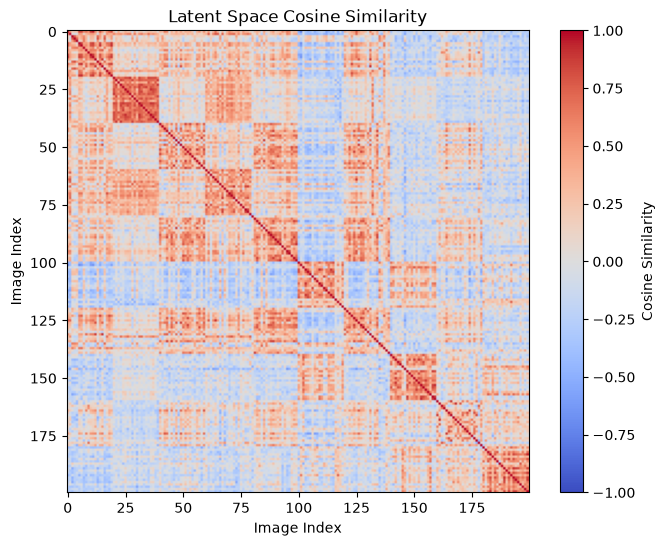

In [394]:
plt.figure(figsize=(8, 6))
plt.imshow(cosine_sim.cpu().numpy(), cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Cosine Similarity")
plt.title("Latent Space Cosine Similarity")
plt.xlabel("Image Index")
plt.ylabel("Image Index")

plt.show()

In [387]:
same_class = y_matrix.unsqueeze(0) == y_matrix.unsqueeze(1)

diagonal = torch.eye(100, dtype=torch.bool, device=device)

intra = cosine_sim[same_class & ~diagonal]
inter = cosine_sim[~same_class]

print("Intra-class:", intra.mean().item())
print("Inter-class:", inter.mean().item())

Intra-class: 0.4409899115562439
Inter-class: -0.05075870081782341


### Try Interpolation between 2 latent representation

In [430]:
## Plot function
def plot_interpolation(img1,img2,img3,curr_class=""):
    # Give the tensor of size 784 as an input 
    img1 = img1.cpu().numpy().reshape(28, 28)
    img2 = img2.cpu().numpy().reshape(28, 28)
    img3 = img3.cpu().numpy().reshape(28, 28)
    plt.figure(figsize=(10, 4))
    plt.suptitle(f"Label: {curr_class}")

    plt.subplot(1, 3, 1)
    plt.imshow(img1)
    plt.title("Image 1")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(img2)
    plt.title("Image 2")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(img3)
    plt.title("(1-alpha)*Img1 + alpha*img2")
    plt.axis('off')
    return plt

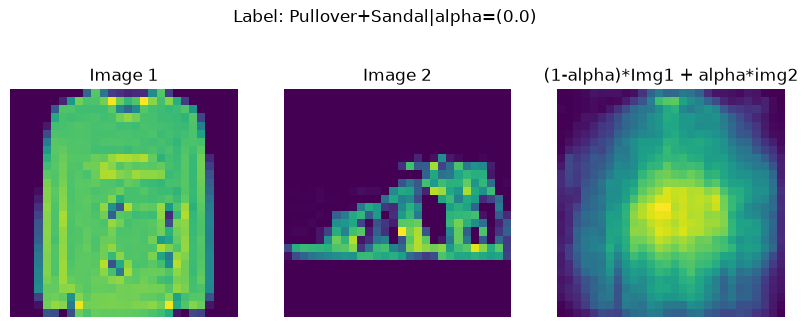

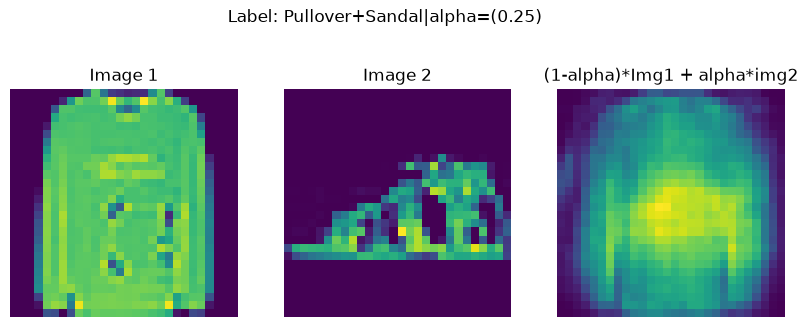

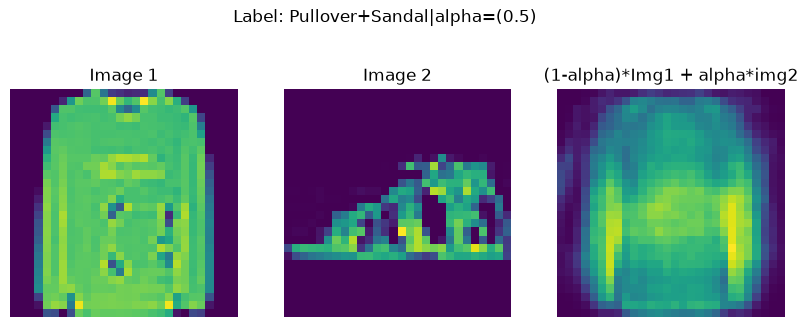

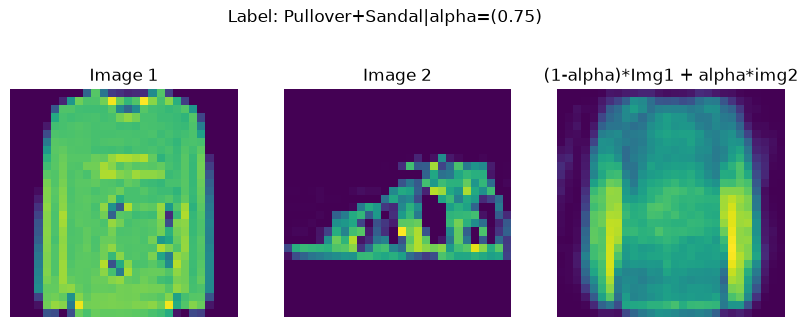

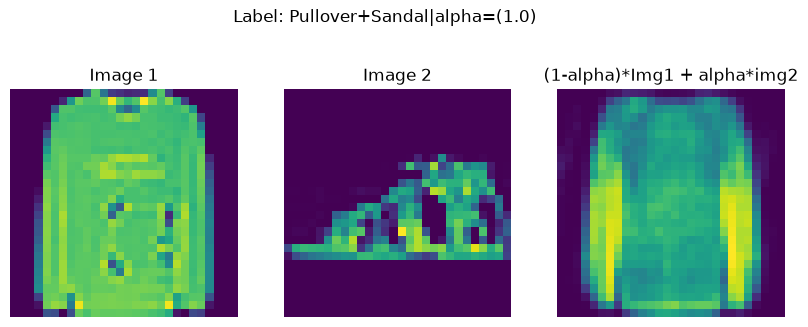

In [ ]:
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]

images, labels = next(iter(test_loader))
classes = test_dataset.classes
selected_labels = [0,1,5,8,9];
for alpha in alphas:
    class1 = 3
    class2 = 5
    # 1. Loop through each of the above class. 
    curr_class = classes[label]
    curr_image_01 = images[labels == class1][3]
    curr_image_02 = images[labels == class2][1]
    image_01_flat = curr_image_01.view(1, -1).to(device)
    image_02_flat = curr_image_02.view(1, -1).to(device)

    with torch.no_grad():
        z1 = model.encoder(image_01_flat)
        z2 = model.encoder(image_02_flat)

        z_alpha = (alpha)*z1 + alpha*z2
        img_rec_interp = model.decoder(z_alpha);
    label_interp = f"{classes[class1]}+{classes[class2]}|alpha=({alpha})";
    plt = plot_interpolation(image_01_flat,image_02_flat,img_rec_interp,label_interp)
